In [77]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import butter, lfilter
from scipy.fft import rfft, rfftfreq
import pickle
import os
from scipy.ndimage import gaussian_filter1d

import matplotlib as mpl
mpl.rcParams['font.size'] = 8.0
mpl.rcParams['pdf.fonttype'] = 42
mpl.rcParams['font.family'] = 'Arial'
%matplotlib inline

In [78]:
out_fig = './dataFolder/Figures/6_GeneratedWhiteNoise/'
os.makedirs(out_fig, exist_ok=True)

In [88]:
Fs = 3e4
Fc = 300 #the max freq the motor could go to
T= 10
preT = 1.1 #gapsbetweenstim
postT = 1.1 
amp = 3 #changeable based on animal- look at animal chart 
seed = 0

In [89]:
pre_pts = int(preT * Fs)
post_pts = int(postT * Fs)
stim_pts = int(T * Fs)
pre_motor = np.zeros(pre_pts)
post_motor = np.zeros(post_pts)
t = np.arange(stim_pts) / Fs

In [90]:
b, a = butter(4, Fc, fs=Fs)

In [91]:
rng = np.random.default_rng(seed)
motor_whitenoise = rng.standard_normal(stim_pts)
motor_whitenoise = lfilter(b, a, motor_whitenoise)
motor_whitenoise = amp * motor_whitenoise / np.max(motor_whitenoise)

In [92]:
motor = np.concatenate([pre_motor, motor_whitenoise, post_motor])

print(f'stim_pts = {stim_pts}, duration = {stim_pts/Fs} s')
print(f'motor_whitenoise: min = {motor_whitenoise.min():.4f} V, '
      f'max = {motor_whitenoise.max():.4f} V, std = {motor_whitenoise.std():.4f} V')
print(f'full trial length = {len(motor)} samples = {len(motor)/Fs:.2f} s')

stim_pts = 300000, duration = 10.0 s
motor_whitenoise: min = -2.9520 V, max = 3.0000 V, std = 0.7882 V
full trial length = 366000 samples = 12.20 s


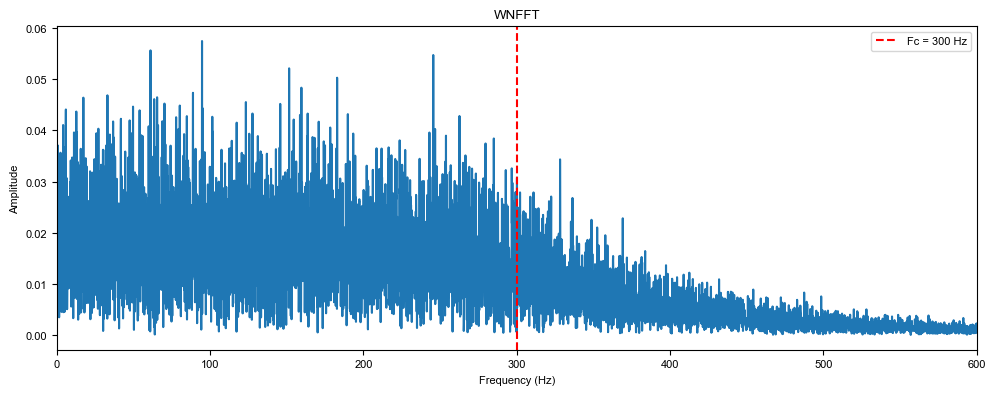

In [93]:
freqs = rfftfreq(stim_pts, 1/Fs)
spectrum = np.abs(rfft(motor_whitenoise)) * 2 / stim_pts
#spectrum_smooth = gaussian_filter1d(spectrum, sigma=5)- is not really making a difference 

plt.figure(figsize=(10, 4))
plt.plot(freqs, spectrum)
plt.axvline(Fc, color='red', linestyle='--', label=f'Fc = {Fc} Hz')
plt.xlim(0, 600)
plt.xlabel('Frequency (Hz)')
plt.ylabel('Amplitude')
plt.title('WNFFT')
plt.legend()
plt.tight_layout()
# plt.savefig(out_fig + f'WNFFT_amp{amp}.pdf')
# plt.savefig(out_fig + f'WNFFT_amp{amp}.png', dpi=300)
plt.show()

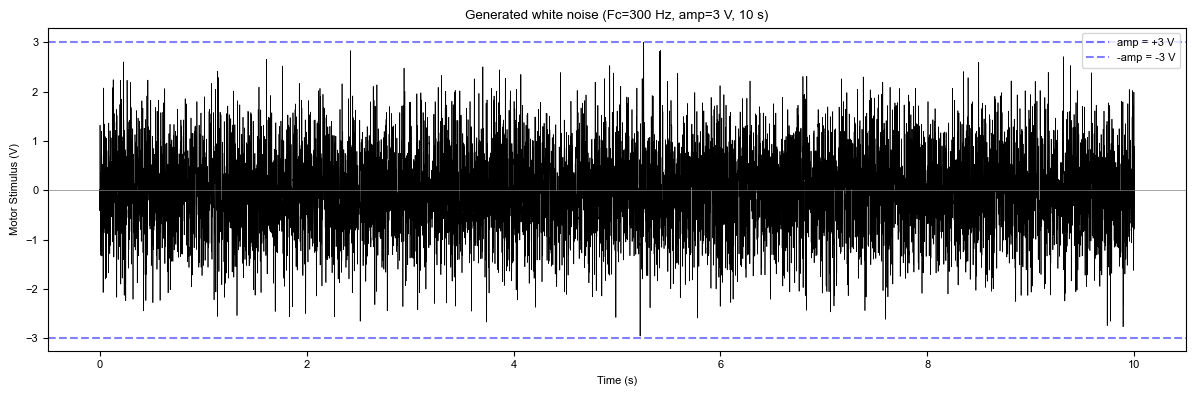

In [94]:
plt.figure(figsize=(12, 4))
plt.plot(t, motor_whitenoise, linewidth=0.5, color='black')
plt.axhline(amp, color='blue', linestyle='--', alpha=0.5, label=f'amp = +{amp} V')
plt.axhline(-amp, color='blue', linestyle='--', alpha=0.5, label=f'-amp = -{amp} V')
plt.axhline(0, color='gray', linewidth=0.5)
plt.xlabel('Time (s)')
plt.ylabel('Motor Stimulus (V)')
plt.title(f'Generated white noise (Fc={Fc} Hz, amp={amp} V, {T} s)')
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()

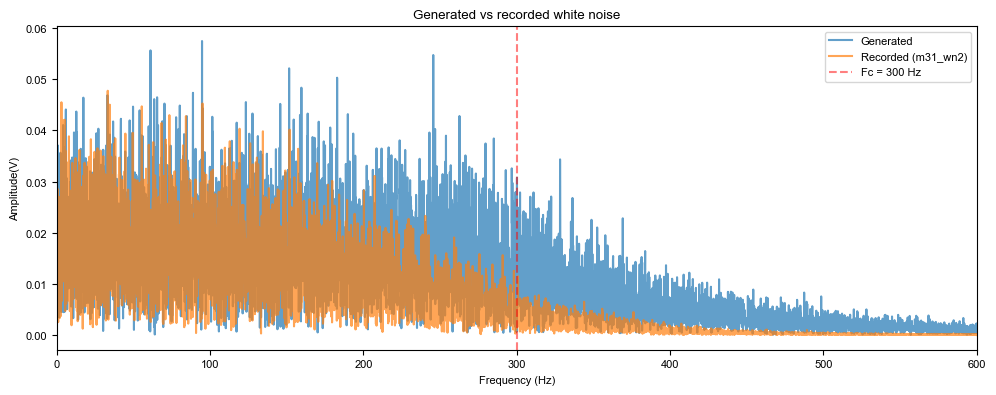

In [96]:
moth = 'm31_wn2'
filepath = f'./dataFolder/4_RawData_Index_Timestamp/ScaledStimulus/{moth}_timeStamps_scaled.pickle'
with open(filepath, 'rb') as f:
    data = pickle.load(f)
recorded = np.array(data[2])

freqs_rec = rfftfreq(len(recorded), 1/Fs)
spec_gen  = np.abs(rfft(motor_whitenoise)) * 2 / stim_pts
spec_rec  = np.abs(rfft(recorded)) * 2 / len(recorded)

plt.figure(figsize=(10, 4))
plt.plot(freqs, spec_gen, label='Generated', alpha=0.7)
plt.plot(freqs_rec, spec_rec, label=f'Recorded ({moth})', alpha=0.7)
plt.axvline(Fc, color='red', linestyle='--', alpha=0.5, label=f'Fc = {Fc} Hz')
plt.xlim(0, 600)
plt.xlabel('Frequency (Hz)')
plt.ylabel('Amplitude(V)')
plt.title('Generated vs recorded white noise')
plt.legend()
plt.tight_layout()
plt.savefig(out_fig + f'GenVsRec_{moth}_amp{amp}.pdf')
plt.savefig(out_fig + f'GenVsRec_{moth}_amp{amp}.png', dpi=300)
plt.show()

In [32]:
moth_amps = {'m23_wn2': 4, 'm29_wn2': 3, 'm30_wn1': 4, 'm31_wn2': 3}

for moth, expected_amp in moth_amps.items():
    filepath = f'./dataFolder/4_RawData_Index_Timestamp/ScaledStimulus/{moth}_timeStamps_scaled.pickle'
    with open(filepath, 'rb') as f:
        data = pickle.load(f)
    recorded = np.array(data[2])
    
    print(f'{moth}: expected amp = {expected_amp} V, '
          f'recorded min = {recorded.min():.3f} V, '
          f'recorded max = {recorded.max():.3f} V')

m23_wn2: expected amp = 4 V, recorded min = -3.643 V, recorded max = 2.929 V
m29_wn2: expected amp = 3 V, recorded min = -2.647 V, recorded max = 2.313 V
m30_wn1: expected amp = 4 V, recorded min = -3.667 V, recorded max = 2.977 V
m31_wn2: expected amp = 3 V, recorded min = -2.666 V, recorded max = 2.303 V
